# Figures for the RKHorn paper

Every figure of the paper is drawn here from data already saved in `../data`. Nothing is simulated in this notebook, so it runs in well under a minute.

| Data | Written by |
|---|---|
| `data/pickle/mesons_*.pkl` | `python simulate_miniboone_meson_fluxes.py` and `python simulate_miniboone_meson_fluxes.py --species pi_plus --horn-current 0` |
| `data/tracks/horn_3d_tracks.npz` | `python simulate_miniboone_meson_fluxes.py --tracks 24` |
| `data/systematics/envelope_*.npz` | `python systematics.py` |
| `data/bsm_data/*.npz` | `python new_physics.py` |

This is the only notebook that saves figures. They go to `../plots/paper` as PDF and PNG.

**Sizes.** Each figure is made at the width it has on the page: `TEXT_WIDTH` (7.0 in) for a figure that spans both columns and `COLUMN_WIDTH` (3.43 in) for a single-column figure. The paper includes them at that width without scaling, so the font and tick sizes set below are the sizes on the page and are the same in every figure. Figures are saved at their exact size (no tight cropping), which is what keeps the scale at one.

**Colors.** Discrete colors come from `tab20c`, which has five hues with four shades each. The darkest shade is used for lines and a light shade of the same hue for the matching uncertainty band.

In [1]:
import os
import sys

from matplotlib import cm
from matplotlib import colors
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import proj3d
import numpy as np

sys.path.append("..")
sys.path.append("../tests")
from constants import BR_K_MUNU, BR_PI_MUNU, M_K, M_PI
import flux_io
from rkhorn import forced_detector_flux, RKHorn
from validate_flux import BIN_EDGES, BIN_WIDTH_GEV, published_per_bin

plt.style.use(os.path.abspath("../custom.mplstyle"))

TEXT_WIDTH = 7.0
COLUMN_WIDTH = 3.43
LABEL_SIZE = 10
TICK_SIZE = 9
LEGEND_SIZE = 8
plt.rcParams.update({
    "font.size": LABEL_SIZE,
    "axes.labelsize": LABEL_SIZE,
    "axes.titlesize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
    "legend.fontsize": LEGEND_SIZE,
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.6,
    "xtick.major.size": 4.0,
    "ytick.major.size": 4.0,
    "xtick.minor.size": 2.0,
    "ytick.minor.size": 2.0,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "figure.dpi": 150,
})

TAB20C = plt.get_cmap("tab20c").colors
BLUE, ORANGE, GREEN, PURPLE, GRAY = (TAB20C[i:i + 4] for i in range(0, 20, 4))
SPECIES_HUE = {"pi_plus": BLUE, "pi_minus": ORANGE, "k_plus": GREEN}

PLOT_DIR = os.path.abspath("../plots/paper")
os.makedirs(PLOT_DIR, exist_ok=True)


def save_figure(fig: plt.Figure, name: str) -> None:
    """Saves a figure at its exact size as PDF and PNG.

    Args:
        fig: Figure to save.
        name: File name without extension.
    """
    for extension in ("pdf", "png"):
        fig.savefig(os.path.join(PLOT_DIR, f"{name}.{extension}"), dpi=300)


def add_grid(ax: plt.Axes, above: bool = False) -> None:
    """Draws thin grid lines at the major ticks.

    Args:
        ax: Axes to draw on.
        above: Draw the grid over the data, as on an image.
    """
    ax.grid(True, linewidth=0.4)
    ax.set_axisbelow(not above)

## Meson samples

Each pickle holds one entry per simulated meson: its momentum and angle at production (`p0`, `theta0`, `weight0`) and at decay (`p`, `theta`, `phi`, the decay position, `weight`). Weights are mesons per proton on target (POT).

In [2]:
NOMINAL_CURRENT = {"pi_plus": 174.0, "k_plus": 174.0, "pi_minus": -174.0}
mesons = {species: flux_io.load_meson_pickle(
              flux_io.pickle_path(species, current))
          for species, current in NOMINAL_CURRENT.items()}
mesons_horn_off = flux_io.load_meson_pickle(
    flux_io.pickle_path("pi_plus", 0.0))

for species, record in mesons.items():
    in_volume = record["decay_in_volume"] > 0.0
    print(f"{species:9s} {record['meta']['n_samples']} sampled, "
          f"{record['weight0'].sum():.4f} produced per POT, "
          f"{record['weight'][in_volume].sum():.4f} decay in the beamline")

pi_plus   150000 sampled, 0.5585 produced per POT, 0.1092 decay in the beamline
k_plus    150000 sampled, 0.0505 produced per POT, 0.0168 decay in the beamline
pi_minus  150000 sampled, 0.4357 produced per POT, 0.0924 decay in the beamline


## Production uncertainty

`systematics.py` varies the parameters of the production fits within their published covariance matrices (1000 throws) and reweights the saved mesons, so the horn tracking is not repeated. Each file holds the nominal spectrum, its standard deviation over the throws and the 16% and 84% quantiles. The bands drawn below are the nominal plus and minus one standard deviation.

In [3]:
envelopes = {species: np.load(f"../data/systematics/envelope_{species}.npz")
             for species in NOMINAL_CURRENT}


def draw_band(ax: plt.Axes, envelope: dict, quantity: str, color: tuple,
              scale: float = 1.0) -> None:
    """Shades nominal plus and minus one standard deviation.

    Args:
        ax: Axes to draw on.
        envelope: Contents of an envelope file.
        quantity: Key prefix, e.g. "pre_horn_p".
        color: Fill color.
        scale: Factor applied to the values.
    """
    nominal = envelope[f"{quantity}_nominal"]*scale
    width = envelope[f"{quantity}_std"]*scale
    ax.stairs(nominal + width, envelope[f"{quantity}_edges"],
              baseline=np.clip(nominal - width, 0.0, None), fill=True,
              color=color, linewidth=0, zorder=1)


print("fractional uncertainty from the production fits")
print("            produced   decaying in beamline   nu flux 0-3 GeV")
for species, envelope in envelopes.items():
    cells = [f"{100*envelope[f'{q}_integral_frac_std']:.1f}%"
             for q in ("pre_horn_p", "post_horn_p", "nu_flux")]
    print(f"{species:9s}   {cells[0]:>6s}          {cells[1]:>6s}"
          f"             {cells[2]:>6s}")

fractional uncertainty from the production fits
            produced   decaying in beamline   nu flux 0-3 GeV
pi_plus      18.1%           21.2%              13.2%
k_plus        7.3%            7.2%               7.0%
pi_minus     18.3%           19.5%              14.6%


## Figure: meson spectra with the production uncertainty

Single-column figure. Dashed lines: momentum spectrum at production, in the sampled range (production angle below 0.6 rad). Solid lines: momentum at decay of the mesons that decay in the open beamline, with the production uncertainty band.

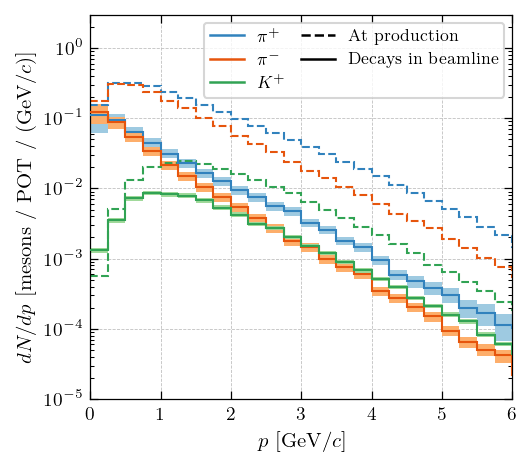

In [4]:
SPECTRA = [("pi_plus", r"$\pi^+$"), ("pi_minus", r"$\pi^-$"),
           ("k_plus", r"$K^+$")]

fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 3.0), layout="constrained")
for species, label in SPECTRA:
    envelope = envelopes[species]
    hue = SPECIES_HUE[species]
    draw_band(ax, envelope, "post_horn_p", hue[2])
    ax.stairs(envelope["pre_horn_p_nominal"], envelope["pre_horn_p_edges"],
              color=hue[0], linestyle="dashed", baseline=None, zorder=2)
    ax.stairs(envelope["post_horn_p_nominal"],
              envelope["post_horn_p_edges"], color=hue[0], baseline=None,
              zorder=3)
handles = [Line2D([], [], color=SPECIES_HUE[species][0], label=label)
           for species, label in SPECTRA]
handles += [
    Line2D([], [], color="k", linestyle="dashed", label="At production"),
    Line2D([], [], color="k", linestyle="solid",
           label="Decays in beamline"),
]
ax.legend(handles=handles, ncol=2, loc="upper right", columnspacing=1.0)
add_grid(ax)
ax.set_yscale("log")
ax.set_xlim(0.0, 6.0)
ax.set_ylim(1e-5, 3.0)
ax.set_xlabel(r"$p$ [GeV$/c$]")
ax.set_ylabel(r"$dN/dp$ [mesons / POT / (GeV$/c$)]")
save_figure(fig, "meson_spectra_systematics")
plt.show()

## Figure: target, horn and tracks in 3D

Two-column figure.

In [5]:
Z_MIN = -0.5
Z_MAX = 3.0
HALF_WIDTH = 0.35
FIELD_STATIONS = (0.4,)
FIELD_RADII = (0.12, 0.22)
ARROWS_PER_RING = 8
TRANSVERSE_STRETCH = 1.6
ARROW_SCALE = 0.3
BEAM_COLOR = ORANGE[0]
FIELD_COLOR = PURPLE[0]
CONDUCTOR_COLOR = GRAY[0]


class Arrow3D(FancyArrowPatch):
    """A filled arrow between two points of a 3D axes."""

    def __init__(self, start: tuple[float, float, float],
                 end: tuple[float, float, float], **kwargs: object) -> None:
        """Initializes the arrow.

        Args:
            start: Tail position in data coordinates.
            end: Head position in data coordinates.
            **kwargs: Passed to FancyArrowPatch.
        """
        super().__init__((0.0, 0.0), (0.0, 0.0), **kwargs)
        self._ends = np.array([start, end]).transpose()

    def do_3d_projection(self, renderer: object = None) -> float:
        """Projects the arrow onto the canvas."""
        x, y, z = proj3d.proj_transform(*self._ends, self.axes.M)
        self.set_positions((x[0], y[0]), (x[1], y[1]))
        return float(np.min(z))


def load_tracks(path: str) -> tuple[list, list, list, np.ndarray]:
    """Reads the saved pion trajectories.

    Args:
        path: File written by simulate_miniboone_meson_fluxes.py.

    Returns:
        The x, y, z histories [m] and initial momenta [MeV].
    """
    saved = np.load(path)
    breaks = np.cumsum(saved["lengths"])[:-1]
    return (np.split(saved["x"], breaks), np.split(saved["y"], breaks),
            np.split(saved["z"], breaks), saved["momenta"])


def extend_track(x: np.ndarray, y: np.ndarray,
                 z: np.ndarray) -> tuple[np.ndarray, ...]:
    """Continues a track in a straight line to Z_MAX.

    Args:
        x: Positions in meters.
        y: Positions in meters.
        z: Positions in meters.

    Returns:
        The x, y, z arrays with one extrapolated point appended.
    """
    if len(z) < 2 or z[-1] <= z[-2] or z[-1] >= Z_MAX:
        return x, y, z
    slope = (Z_MAX - z[-1]) / (z[-1] - z[-2])
    return (np.append(x, x[-1] + slope*(x[-1] - x[-2])),
            np.append(y, y[-1] + slope*(y[-1] - y[-2])),
            np.append(z, Z_MAX))


def transverse_momentum(x: np.ndarray, y: np.ndarray, z: np.ndarray,
                        momentum: float) -> float:
    """Transverse momentum at production, from the first step.

    Args:
        x: Positions in meters.
        y: Positions in meters.
        z: Positions in meters.
        momentum: Momentum at production.

    Returns:
        The momentum component transverse to the beam axis.
    """
    step = np.array([x[1] - x[0], y[1] - y[0], z[1] - z[0]])
    return momentum*np.hypot(step[0], step[1])/np.linalg.norm(step)


def draw_conductors(ax: plt.Axes, solver: RKHorn) -> None:
    """Draws the inner conductor, outer conductor and target.

    Args:
        ax: The 3D axes.
        solver: The tracker holding the horn geometry.
    """
    z = np.linspace(solver.horn_start, solver.horn_end, 120)
    phi = np.linspace(0.0, 2*np.pi, 60)
    z_grid, phi_grid = np.meshgrid(z, phi)
    r_grid = solver.inner_radius(z_grid)
    ax.plot_surface(z_grid, r_grid*np.cos(phi_grid), r_grid*np.sin(phi_grid),
                    color=CONDUCTOR_COLOR, alpha=0.3, linewidth=0,
                    antialiased=True, shade=True)
    r_out = solver.horn_max_radius
    for z_ring in np.linspace(solver.horn_start, solver.horn_end, 4):
        ax.plot(np.full_like(phi, z_ring), r_out*np.cos(phi),
                r_out*np.sin(phi), color=CONDUCTOR_COLOR, linewidth=0.5)
    for phi_line in np.linspace(0.0, 2*np.pi, 8, endpoint=False):
        ax.plot([solver.horn_start, solver.horn_end],
                [r_out*np.cos(phi_line)]*2, [r_out*np.sin(phi_line)]*2,
                color=CONDUCTOR_COLOR, linewidth=0.3, alpha=0.6)
    ax.plot([0.0, solver.target_length], [0.0, 0.0], [0.0, 0.0],
            color="k", linewidth=1.6)


def draw_field(ax: plt.Axes, solver: RKHorn) -> None:
    """Draws arrows along the field between the conductors.

    Args:
        ax: The 3D axes.
        solver: The tracker holding the geometry and current.
    """
    phi = np.linspace(0.0, 2*np.pi, ARROWS_PER_RING, endpoint=False)
    ring = np.linspace(0.0, 2*np.pi, 80)
    for z_station in FIELD_STATIONS:
        for radius in FIELD_RADII:
            if radius <= solver.inner_radius(z_station):
                continue
            x, y = radius*np.cos(phi), radius*np.sin(phi)
            field = np.array([solver.bfield(xi, yi, z_station)
                              for xi, yi in zip(x, y)])
            ax.plot(np.full_like(ring, z_station), radius*np.cos(ring),
                    radius*np.sin(ring), color=FIELD_COLOR, linewidth=0.3,
                    alpha=0.5)
            ax.quiver(np.full_like(x, z_station), x, y, field[:, 2],
                      field[:, 0], field[:, 1], length=ARROW_SCALE,
                      color=FIELD_COLOR, linewidth=0.9,
                      arrow_length_ratio=0.45)

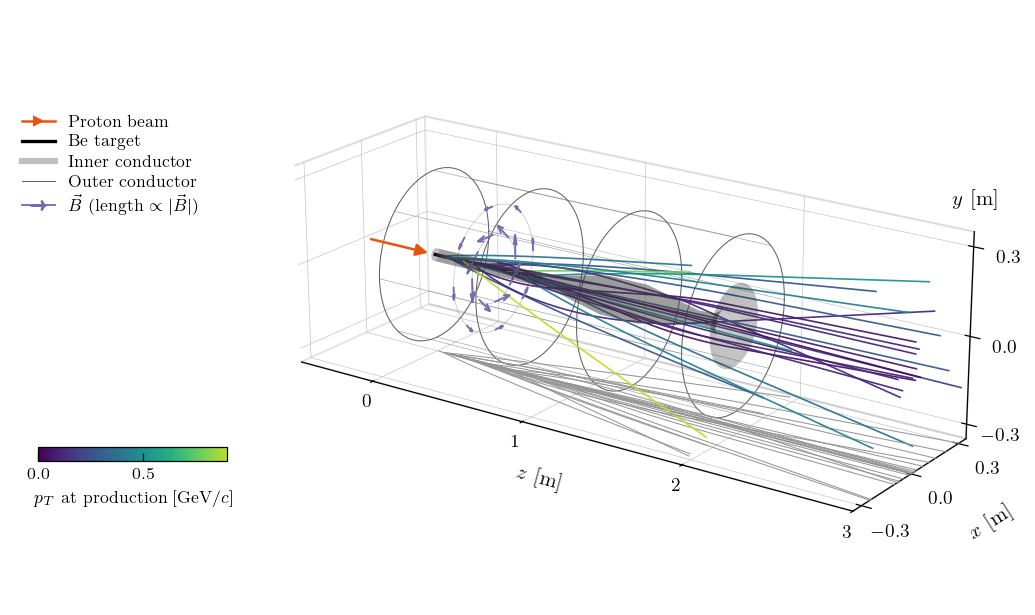

In [6]:
xs, ys, zs, momenta = load_tracks("../data/tracks/horn_3d_tracks.npz")
solver = RKHorn(horn_current=174.0)

fig = plt.figure(figsize=(TEXT_WIDTH, 3.0))
with plt.rc_context({"grid.linewidth": 0.3, "grid.linestyle": "solid"}):
    ax = fig.add_axes([0.05, -0.11, 1.06, 1.30], projection="3d")
draw_conductors(ax, solver)
draw_field(ax, solver)
ax.add_artist(Arrow3D((-0.45, 0.0, 0.0), (-0.05, 0.0, 0.0),
                      arrowstyle="-|>", mutation_scale=12, linewidth=1.2,
                      color=BEAM_COLOR, shrinkA=0, shrinkB=0))

norm = colors.Normalize(vmin=0.0, vmax=0.9)
cmap = colors.LinearSegmentedColormap.from_list(
    "viridis_truncated", plt.get_cmap("viridis")(np.linspace(0.0, 0.9, 256)))
for x, y, z, p in zip(xs, ys, zs, momenta):
    p_t = transverse_momentum(x, y, z, p)
    x, y, z = extend_track(x, y, z)
    inside = (np.abs(x) < HALF_WIDTH) & (np.abs(y) < HALF_WIDTH)
    end = len(z) if inside.all() else int(np.argmin(inside))
    ax.plot(z[:end], x[:end], np.full(end, -HALF_WIDTH), color=GRAY[1],
            linewidth=0.5, clip_on=False)
    ax.plot(z[:end], x[:end], y[:end], color=cmap(norm(p_t/1.0e3)),
            linewidth=0.8, alpha=0.95, clip_on=False)

ax.set_xlim(Z_MIN, Z_MAX)
ax.set_ylim(-HALF_WIDTH, HALF_WIDTH)
ax.set_zlim(-HALF_WIDTH, HALF_WIDTH)
transverse = 2*HALF_WIDTH*TRANSVERSE_STRETCH
ax.set_box_aspect((Z_MAX - Z_MIN, transverse, transverse), zoom=1.22)
ax.view_init(elev=20, azim=-55)
ax.set_xlabel(r"$z$ [m]", labelpad=4)
ax.set_ylabel(r"$x$ [m]", labelpad=-2)
ax.text(Z_MAX, HALF_WIDTH, 1.3*HALF_WIDTH, r"$y$ [m]", ha="center",
        va="center", clip_on=False)
ax.set_xticks([0.0, 1.0, 2.0, 3.0])
ax.set_yticks([-0.3, 0.0, 0.3])
ax.set_zticks([-0.3, 0.0, 0.3])
ax.tick_params(pad=-1)
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.pane.set_facecolor("white")
    axis.pane.set_edgecolor(GRAY[2])
ax.grid(True)

handles = [
    Line2D([], [], color=BEAM_COLOR, linewidth=1.2, marker=">",
           markersize=4, label="Proton beam"),
    Line2D([], [], color="k", linewidth=1.6, label="Be target"),
    Line2D([], [], color=CONDUCTOR_COLOR, linewidth=3, alpha=0.4,
           label="Inner conductor"),
    Line2D([], [], color=CONDUCTOR_COLOR, linewidth=0.5,
           label="Outer conductor"),
    Line2D([], [], color=FIELD_COLOR, linewidth=0.9,
           marker=r"$\rightarrow$", markersize=7,
           label=r"$\vec{B}$ (length $\propto |\vec{B}|$)"),
]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 1.0),
           frameon=False, labelspacing=0.3)
colorbar_ax = fig.add_axes([0.03, 0.2, 0.18, 0.03])
colorbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),
                        cax=colorbar_ax, orientation="horizontal")
colorbar.set_label(r"$p_T$ at production [GeV$/c$]",
                   fontsize=LEGEND_SIZE)
colorbar.ax.tick_params(labelsize=LEGEND_SIZE)
save_figure(fig, "horn_3d")
plt.show()

## Figure: focusing of $\pi^+$

Two-column figure. The horn-off and horn-on samples use the same random seeds, so they contain the same produced pions and differ only by the field.

Horn off: 0.00067 pi+/POT below 10 mrad
Horn off: 0.01828 pi+/POT below 50 mrad
Horn on, $I = 174$ kA: 0.02795 pi+/POT below 10 mrad
Horn on, $I = 174$ kA: 0.12705 pi+/POT below 50 mrad


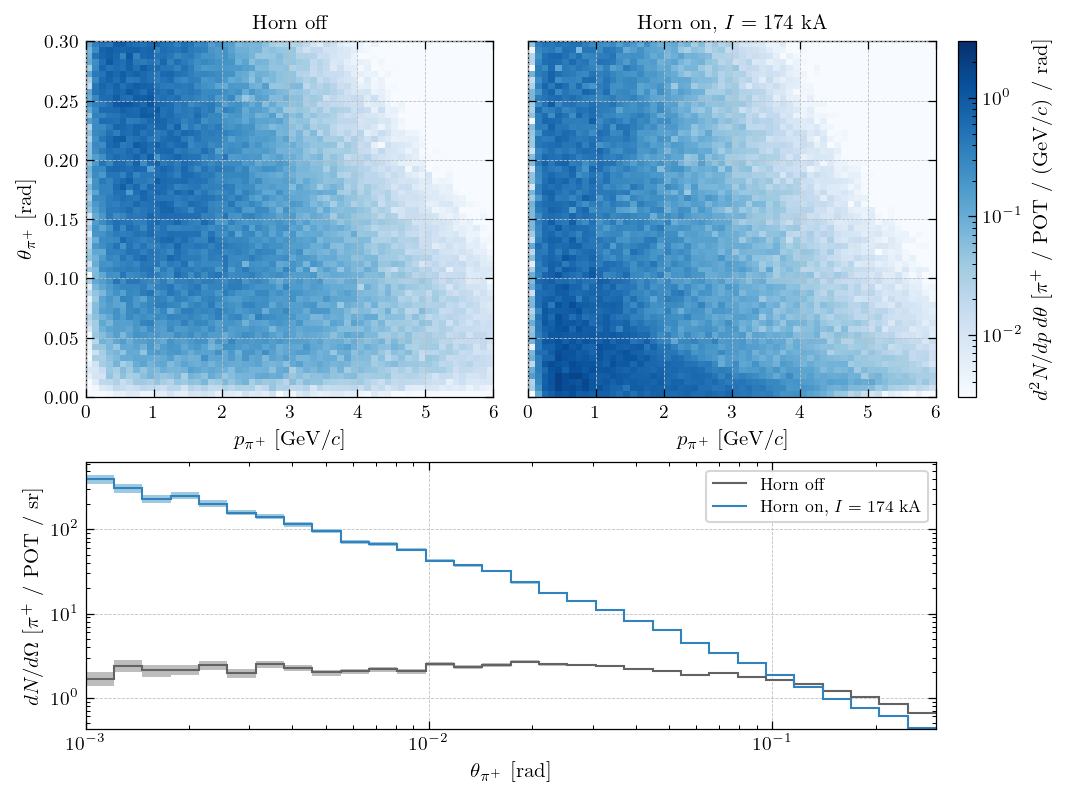

In [7]:
P_EDGES = np.linspace(0.0, 6.0, 61)
THETA_EDGES = np.linspace(0.0, 0.3, 61)
LOG_THETA_EDGES = np.logspace(-3, np.log10(0.3), 31)
FOCUS_SAMPLES = [("Horn off", mesons_horn_off, GRAY),
                 (r"Horn on, $I = 174$ kA", mesons["pi_plus"], BLUE)]

fig = plt.figure(figsize=(TEXT_WIDTH, 5.2), layout="constrained")
grid = fig.add_gridspec(2, 2, height_ratios=[1.0, 0.75])
ax_off = fig.add_subplot(grid[0, 0])
ax_on = fig.add_subplot(grid[0, 1], sharey=ax_off)
ax_wide = fig.add_subplot(grid[1, :])
ax_on.tick_params(labelleft=False)

bin_area = (P_EDGES[1] - P_EDGES[0]) * (THETA_EDGES[1] - THETA_EDGES[0])
solid_angle = 2*np.pi*(np.cos(LOG_THETA_EDGES[:-1])
                       - np.cos(LOG_THETA_EDGES[1:]))
for ax, (title, record, hue) in zip((ax_off, ax_on), FOCUS_SAMPLES):
    moving = record["p"] > 0.0
    p = record["p"][moving]*1.0e-3
    theta = record["theta"][moving]
    weight = record["weight"][moving].astype(float)
    image = ax.hist2d(p, theta, weights=weight/bin_area,
                      bins=[P_EDGES, THETA_EDGES], cmap="Blues",
                      norm=colors.LogNorm(vmin=3e-3, vmax=3.0),
                      rasterized=True)[3]
    ax.set_facecolor(plt.get_cmap("Blues")(0.0))
    ax.set_title(title)
    ax.set_xlabel(r"$p_{\pi^+}$ [GeV$/c$]")
    add_grid(ax, above=True)
    for cut in (0.01, 0.05):
        print(f"{title}: {weight[theta < cut].sum():.5f} pi+/POT "
              f"below {1e3*cut:.0f} mrad")

    hist, _ = np.histogram(theta, weights=weight, bins=LOG_THETA_EDGES)
    hist_sq, _ = np.histogram(theta, weights=weight**2,
                              bins=LOG_THETA_EDGES)
    density, error = hist/solid_angle, np.sqrt(hist_sq)/solid_angle
    ax_wide.stairs(density + error, LOG_THETA_EDGES,
                   baseline=density - error, fill=True, color=hue[2],
                   linewidth=0, zorder=1)
    ax_wide.stairs(density, LOG_THETA_EDGES, color=hue[0], label=title,
                   baseline=None, zorder=2)

ax_off.set_ylabel(r"$\theta_{\pi^+}$ [rad]")
colorbar = fig.colorbar(image, ax=[ax_off, ax_on], pad=0.02)
colorbar.set_label(
    r"$d^2N / dp \, d\theta$ [$\pi^+$ / POT / (GeV$/c$) / rad]")
ax_wide.set_xscale("log")
ax_wide.set_yscale("log")
ax_wide.set_xlim(LOG_THETA_EDGES[0], LOG_THETA_EDGES[-1])
ax_wide.set_xlabel(r"$\theta_{\pi^+}$ [rad]")
ax_wide.set_ylabel(r"$dN / d\Omega$ [$\pi^+$ / POT / sr]")
ax_wide.legend(loc="upper right")
add_grid(ax_wide)
save_figure(fig, "focusing_2d")
plt.show()

## Figure and table: neutrino flux at MiniBooNE

Single-column figure. `forced_detector_flux` turns every decayed meson into one weighted neutrino at the detector (541 m downstream, on axis). The published curves are the pion-parent components of the MiniBooNE flux prediction, integrated over the same 50 MeV bins. The shaded bands are the production uncertainty of the RKHorn flux.

In [8]:
DECAYS = {"pi_plus": (M_PI, BR_PI_MUNU), "pi_minus": (M_PI, BR_PI_MUNU),
          "k_plus": (M_K, BR_K_MUNU)}
REFERENCE_FILES = {"pi_plus": "numu_diff_flux_by_POT_GeV_cm2.txt",
                   "pi_minus": "numubar_diff_flux_by_POT_GeV_cm2.txt"}
BANDS = [(0, 3000), (0, 500), (500, 1000), (1000, 1500), (1500, 2000),
         (2000, 3000)]
REBIN = 4

flux, flux_sq = {}, {}
for species, (mass, branching) in DECAYS.items():
    e_nu, w_nu = forced_detector_flux(flux_io.flux_array(mesons[species]),
                                      m_meson=mass, br=branching)
    flux[species] = np.histogram(e_nu, weights=w_nu, bins=BIN_EDGES)[0]
    flux_sq[species] = np.histogram(e_nu, weights=w_nu**2, bins=BIN_EDGES)[0]
reference = {species: published_per_bin(filename)
             for species, filename in REFERENCE_FILES.items()}

print("RKHorn / published, by neutrino energy [MeV]")
print("   band        nu_mu (pi+)      nu_mubar (pi-)")
for low, high in BANDS:
    selected = (BIN_EDGES[:-1] >= low) & (BIN_EDGES[1:] <= high)
    cells = []
    for species in ("pi_plus", "pi_minus"):
        ref_sum = reference[species][selected].sum()
        ratio = flux[species][selected].sum()/ref_sum
        error = np.sqrt(flux_sq[species][selected].sum())/ref_sum
        cells.append(f"{ratio:.2f} +- {error:.2f}")
    print(f"{low:5d}-{high:5d}   {cells[0]}     {cells[1]}")
print(f"K+ -> mu nu below 3 GeV: {flux['k_plus'].sum():.3e} nu/cm^2/POT")

RKHorn / published, by neutrino energy [MeV]
   band        nu_mu (pi+)      nu_mubar (pi-)
    0- 3000   1.20 +- 0.02     1.14 +- 0.02
    0-  500   0.93 +- 0.02     0.88 +- 0.02
  500- 1000   1.15 +- 0.03     1.19 +- 0.03
 1000- 1500   1.46 +- 0.05     1.51 +- 0.05
 1500- 2000   1.90 +- 0.10     2.22 +- 0.12
 2000- 3000   1.90 +- 0.18     1.76 +- 0.20
K+ -> mu nu below 3 GeV: 9.039e-12 nu/cm^2/POT


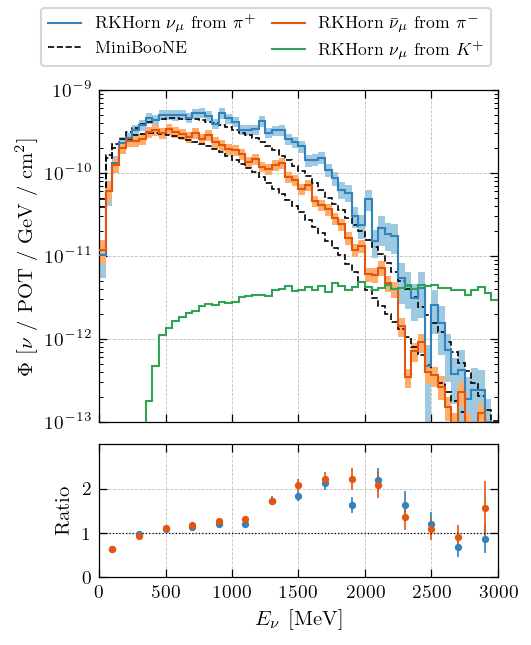

In [9]:
wide_edges = BIN_EDGES[::REBIN]
wide_centers = 0.5*(wide_edges[1:] + wide_edges[:-1])
curves = [("pi_plus", r"$\nu_\mu$ from $\pi^+$"),
          ("pi_minus", r"$\bar{\nu}_\mu$ from $\pi^-$")]

fig, (ax, ax_ratio) = plt.subplots(
    2, 1, figsize=(COLUMN_WIDTH, 4.2), sharex=True, layout="constrained",
    gridspec_kw={"height_ratios": [3, 1.2]})
for species, name in curves:
    hue = SPECIES_HUE[species]
    draw_band(ax, envelopes[species], "nu_flux", hue[2], 1.0/BIN_WIDTH_GEV)
    ax.stairs(flux[species]/BIN_WIDTH_GEV, BIN_EDGES, color=hue[0],
              label=f"RKHorn {name}", baseline=None, zorder=3)
    ax.stairs(reference[species]/BIN_WIDTH_GEV, BIN_EDGES, color="k",
              linestyle="dashed", linewidth=0.8, baseline=None, zorder=2,
              label="MiniBooNE" if species == "pi_plus" else None)
    ref_wide = reference[species].reshape(-1, REBIN).sum(axis=1)
    ratio = flux[species].reshape(-1, REBIN).sum(axis=1)/ref_wide
    error = np.sqrt(flux_sq[species].reshape(-1, REBIN).sum(axis=1))/ref_wide
    ax_ratio.errorbar(wide_centers, ratio, yerr=error, color=hue[0],
                      marker="o", markersize=2.5, linewidth=0.8,
                      linestyle="none")
ax.stairs(flux["k_plus"]/BIN_WIDTH_GEV, BIN_EDGES,
          color=SPECIES_HUE["k_plus"][0], baseline=None, zorder=3,
          label=r"RKHorn $\nu_\mu$ from $K^+$")
ax.set_yscale("log")
ax.set_xlim(BIN_EDGES[0], BIN_EDGES[-1])
ax.set_ylim(1e-13, 1e-9)
ax.set_ylabel(r"$\Phi$ [$\nu$ / POT / GeV / cm$^2$]")
fig.legend(loc="outside upper center", ncol=2, columnspacing=1.0)
ax_ratio.axhline(1.0, color="k", linestyle="dotted", linewidth=0.6)
ax_ratio.set_ylim(0.0, 3.0)
ax_ratio.set_yticks([0.0, 1.0, 2.0])
ax_ratio.set_xlabel(r"$E_\nu$ [MeV]")
ax_ratio.set_ylabel("Ratio")
add_grid(ax)
add_grid(ax_ratio)
save_figure(fig, "flux_validation")
plt.show()

## Figure: new-physics fluxes at SBND

Two-column figure. `new_physics.py` computes two benchmark fluxes at SBND (110 m from the target, on the beam axis) from the saved mesons in neutrino mode.

- A vector $Z'$ coupled to the muon and its neutrino, made in $\pi^+, K^+ \to \mu^+ \nu_\mu Z'$, which decays promptly to dark matter, $Z' \to \chi \bar{\chi}$.
- A Higgs-portal scalar $S$ with mixing angle $\theta$, made in $K^+ \to \pi^+ S$ and in $\pi^+ \to \ell^+ \nu S$, which is long-lived.

The fluxes scale with the square of the coupling. Color is the mass of the new particle; the line style is the parent meson.

In [10]:
BSM_DIR = "../data/bsm_data"
ZPRIME_MASSES = (10, 20, 30)
SCALAR_MASSES = (10, 50, 100)
MASS_HUES = (BLUE, ORANGE, GREEN)
PARENT_STYLE = {"k_plus": "solid", "pi_plus": "dashed"}


def load_bsm(model: str, species: str, mass: int) -> dict:
    """Reads one new-physics flux file in neutrino mode.

    Args:
        model: "zprime_dm" or "higgs_scalar".
        species: Parent meson, "pi_plus" or "k_plus".
        mass: Mass of the new particle in MeV.

    Returns:
        The contents of the file.
    """
    tag = "mzp" if model == "zprime_dm" else "ms"
    name = f"{model}_{species}_+174kA_{tag}{mass}MeV.npz"
    return np.load(os.path.join(BSM_DIR, name), allow_pickle=True)


print("model, parent, mass [MeV]: BR, flux at SBND centre [1/cm^2/POT]")
for model, masses in (("zprime_dm", ZPRIME_MASSES),
                      ("higgs_scalar", SCALAR_MASSES)):
    for species in ("pi_plus", "k_plus"):
        for mass in masses:
            data = load_bsm(model, species, mass)
            print(f"{model:13s} {species:8s} {mass:4d}: "
                  f"{float(data['branching_ratio']):.2e}  "
                  f"{float(data['flux_centre_total_per_pot_cm2']):.2e} +- "
                  f"{float(data['flux_centre_total_err']):.1e}")

model, parent, mass [MeV]: BR, flux at SBND centre [1/cm^2/POT]
zprime_dm     pi_plus    10: 1.60e-10  8.53e-18 +- 1.4e-19
zprime_dm     pi_plus    20: 1.30e-11  7.91e-19 +- 1.4e-20
zprime_dm     pi_plus    30: 1.04e-13  6.09e-21 +- 9.9e-23
zprime_dm     k_plus     10: 2.13e-09  2.87e-18 +- 2.5e-20
zprime_dm     k_plus     20: 1.33e-09  1.85e-18 +- 1.5e-20
zprime_dm     k_plus     30: 9.43e-10  1.35e-18 +- 1.1e-20
higgs_scalar  pi_plus    10: 1.86e-17  3.85e-25 +- 6.2e-27
higgs_scalar  pi_plus    50: 7.62e-18  2.53e-25 +- 4.1e-27
higgs_scalar  pi_plus   100: 2.81e-19  3.46e-26 +- 7.8e-28
higgs_scalar  k_plus     10: 1.83e-11  1.13e-20 +- 9.3e-23
higgs_scalar  k_plus     50: 1.80e-11  1.14e-20 +- 9.4e-23
higgs_scalar  k_plus    100: 1.73e-11  1.19e-20 +- 9.7e-23


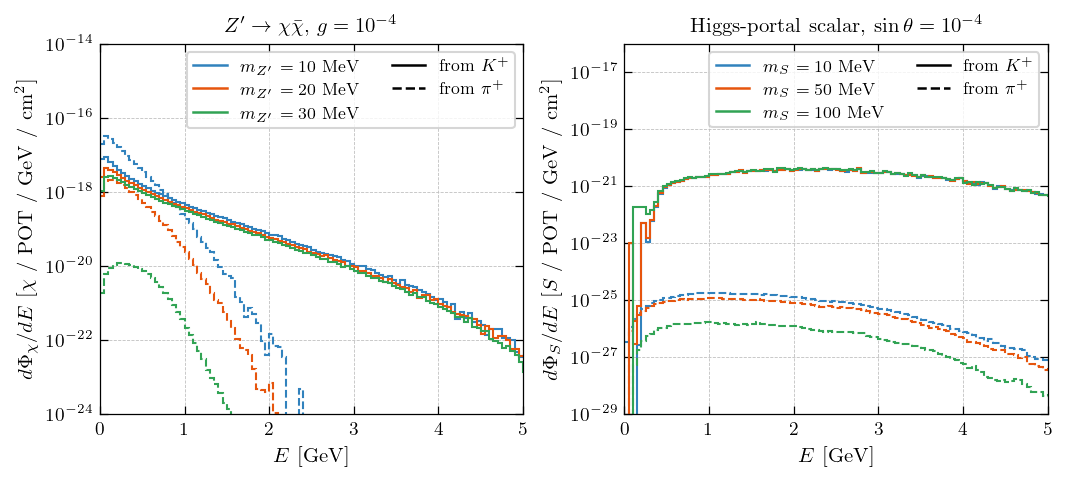

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 3.1),
                         layout="constrained")
panels = [(axes[0], "zprime_dm", ZPRIME_MASSES, r"$m_{Z'}$"),
          (axes[1], "higgs_scalar", SCALAR_MASSES, r"$m_S$")]
for ax, model, masses, symbol in panels:
    for mass, hue in zip(masses, MASS_HUES):
        for species, linestyle in PARENT_STYLE.items():
            data = load_bsm(model, species, mass)
            edges = data["energy_edges_mev"]*1.0e-3
            ax.stairs(data["flux_centre_per_pot_cm2"]/np.diff(edges), edges,
                      color=hue[0], linestyle=linestyle, baseline=None)
    mass_handles = [Line2D([], [], color=hue[0],
                           label=rf"{symbol} $= {mass}$ MeV")
                    for mass, hue in zip(masses, MASS_HUES)]
    parent_handles = [
        Line2D([], [], color="k", linestyle="solid", label=r"from $K^+$"),
        Line2D([], [], color="k", linestyle="dashed", label=r"from $\pi^+$"),
    ]
    ax.legend(handles=mass_handles + parent_handles, ncol=2,
              loc="upper right")
    ax.set_yscale("log")
    ax.set_xlim(0.0, 5.0)
    ax.set_xlabel(r"$E$ [GeV]")
    add_grid(ax)
axes[0].set_ylim(1e-24, 1e-14)
axes[0].set_ylabel(r"$d\Phi_\chi / dE$ [$\chi$ / POT / GeV / cm$^2$]")
axes[0].set_title(r"$Z' \to \chi\bar{\chi}$, $g = 10^{-4}$")
axes[1].set_ylim(1e-29, 1e-16)
axes[1].set_ylabel(r"$d\Phi_S / dE$ [$S$ / POT / GeV / cm$^2$]")
axes[1].set_title(r"Higgs-portal scalar, $\sin\theta = 10^{-4}$")
save_figure(fig, "bsm_fluxes_sbnd")
plt.show()